In [2]:
!pip -q install pybullet

  Preparing metadata (setup.py) ... done


In [3]:
import os
import math
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import pybullet as p
import pybullet_data

from pathlib import Path
from IPython.display import display, Image

In [4]:
print("PyBullet version:", p.__version__ if hasattr(p, "__version__") else "Installed")
print("NumPy version:", np.__version__)

PyBullet version: Installed
NumPy version: 2.1.3


In [5]:
BASE_DIR = Path("/content/pybullet_semantic_warehouse")
URDF_DIR = BASE_DIR / "urdf"
OUTPUT_DIR = BASE_DIR / "outputs"

URDF_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Base directory:", BASE_DIR)
print("URDF directory:", URDF_DIR)
print("Output directory:", OUTPUT_DIR)

Base directory: /content/pybullet_semantic_warehouse
URDF directory: /content/pybullet_semantic_warehouse/urdf
Output directory: /content/pybullet_semantic_warehouse/outputs


In [6]:
wall_urdf = """
<?xml version="1.0"?>
<robot name="warehouse_wall">

  <link name="wall_link">

    <visual>
      <origin xyz="0 0 1.0"/>
      <geometry>
        <box size="4.0 0.25 2.0"/>
      </geometry>
      <material name="wall_material">
        <color rgba="0.35 0.35 0.35 1"/>
      </material>
    </visual>

    <collision>
      <origin xyz="0 0 1.0"/>
      <geometry>
        <box size="4.0 0.25 2.0"/>
      </geometry>
    </collision>

    <inertial>
      <mass value="20"/>
      <inertia ixx="10" ixy="0" ixz="0"
               iyy="10" iyz="0"
               izz="10"/>
    </inertial>

  </link>
</robot>
"""

with open(URDF_DIR / "wall.urdf", "w") as f:
    f.write(wall_urdf)

print("Wall URDF created.")

Wall URDF created.


In [7]:
storage_urdf = """
<?xml version="1.0"?>
<robot name="storage_block">

  <link name="storage_link">

    <visual>
      <origin xyz="0 0 0.75"/>
      <geometry>
        <box size="1.5 1.2 1.5"/>
      </geometry>
      <material name="storage_material">
        <color rgba="0.55 0.32 0.15 1"/>
      </material>
    </visual>

    <collision>
      <origin xyz="0 0 0.75"/>
      <geometry>
        <box size="1.5 1.2 1.5"/>
      </geometry>
    </collision>

    <inertial>
      <mass value="15"/>
      <inertia ixx="5" ixy="0" ixz="0"
               iyy="5" iyz="0"
               izz="5"/>
    </inertial>

  </link>
</robot>
"""

with open(URDF_DIR / "storage_block.urdf", "w") as f:
    f.write(storage_urdf)

print("Storage block URDF created.")

Storage block URDF created.


In [8]:
target_urdf = """
<?xml version="1.0"?>
<robot name="target_zone">

  <link name="target_link">

    <visual>
      <origin xyz="0 0 0.025"/>
      <geometry>
        <box size="2.0 2.0 0.05"/>
      </geometry>
      <material name="target_material">
        <color rgba="0.1 0.8 0.2 1"/>
      </material>
    </visual>

    <collision>
      <origin xyz="0 0 0.025"/>
      <geometry>
        <box size="2.0 2.0 0.05"/>
      </geometry>
    </collision>

    <inertial>
      <mass value="1"/>
      <inertia ixx="0.1" ixy="0" ixz="0"
               iyy="0.1" iyz="0"
               izz="0.1"/>
    </inertial>

  </link>
</robot>
"""

with open(URDF_DIR / "target_zone.urdf", "w") as f:
    f.write(target_urdf)

print("Target zone URDF created.")

Target zone URDF created.


In [9]:
landmark_urdf = """
<?xml version="1.0"?>
<robot name="landmark">

  <link name="landmark_link">

    <visual>
      <origin xyz="0 0 1.0"/>
      <geometry>
        <cylinder radius="0.35" length="2.0"/>
      </geometry>
      <material name="landmark_material">
        <color rgba="0.15 0.35 0.9 1"/>
      </material>
    </visual>

    <collision>
      <origin xyz="0 0 1.0"/>
      <geometry>
        <cylinder radius="0.35" length="2.0"/>
      </geometry>
    </collision>

    <inertial>
      <mass value="5"/>
      <inertia ixx="1" ixy="0" ixz="0"
               iyy="1" iyz="0"
               izz="1"/>
    </inertial>

  </link>
</robot>
"""

with open(URDF_DIR / "landmark.urdf", "w") as f:
    f.write(landmark_urdf)

print("Landmark URDF created.")

Landmark URDF created.


In [10]:
robot_urdf = """
<?xml version="1.0"?>
<robot name="semantic_two_wheel_robot">

  <link name="base_link">

    <visual>
      <origin xyz="0 0 0.25"/>
      <geometry>
        <box size="1.0 0.7 0.35"/>
      </geometry>
      <material name="robot_body">
        <color rgba="0.75 0.75 0.75 1"/>
      </material>
    </visual>

    <collision>
      <origin xyz="0 0 0.25"/>
      <geometry>
        <box size="1.0 0.7 0.35"/>
      </geometry>
    </collision>

    <inertial>
      <origin xyz="0 0 0.25"/>
      <mass value="5"/>
      <inertia ixx="0.5" ixy="0" ixz="0"
               iyy="0.5" iyz="0"
               izz="0.5"/>
    </inertial>

  </link>

  <link name="left_wheel">
    <visual>
      <origin xyz="0 0 0"/>
      <geometry>
        <cylinder radius="0.22" length="0.12"/>
      </geometry>
      <material name="wheel_material">
        <color rgba="0.05 0.05 0.05 1"/>
      </material>
    </visual>
    <collision>
      <origin xyz="0 0 0"/>
      <geometry>
        <cylinder radius="0.22" length="0.12"/>
      </geometry>
    </collision>
    <inertial>
      <mass value="0.5"/>
      <inertia ixx="0.05" ixy="0" ixz="0"
               iyy="0.05" iyz="0"
               izz="0.05"/>
    </inertial>
  </link>

  <link name="right_wheel">
    <visual>
      <origin xyz="0 0 0"/>
      <geometry>
        <cylinder radius="0.22" length="0.12"/>
      </geometry>
      <material name="wheel_material2">
        <color rgba="0.05 0.05 0.05 1"/>
      </material>
    </visual>
    <collision>
      <origin xyz="0 0 0"/>
      <geometry>
        <cylinder radius="0.22" length="0.12"/>
      </geometry>
    </collision>
    <inertial>
      <mass value="0.5"/>
      <inertia ixx="0.05" ixy="0" ixz="0"
               iyy="0.05" iyz="0"
               izz="0.05"/>
    </inertial>
  </link>

  <joint name="left_wheel_joint"
         type="continuous">
    <parent link="base_link"/>
    <child link="left_wheel"/>
    <origin xyz="0 0.42 0.22"/>
    <axis xyz="0 1 0"/>
  </joint>

  <joint name="right_wheel_joint"
         type="continuous">
    <parent link="base_link"/>
    <child link="right_wheel"/>
    <origin xyz="0 -0.42 0.22"/>
    <axis xyz="0 1 0"/>
  </joint>

</robot>
"""

with open(URDF_DIR / "two_wheel_robot.urdf", "w") as f:
    f.write(robot_urdf)

print("Two-wheel robot URDF created.")

Two-wheel robot URDF created.


In [11]:
print("Created URDF files:")

for file in URDF_DIR.glob("*.urdf"):
    print(" -", file.name)

Created URDF files:
 - storage_block.urdf
 - two_wheel_robot.urdf
 - landmark.urdf
 - target_zone.urdf
 - wall.urdf


In [12]:
physics_client = p.connect(p.DIRECT)

p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.setGravity(0, 0, -9.81)

print("PyBullet connection mode: DIRECT")
print("Physics client ID:", physics_client)

PyBullet connection mode: DIRECT
Physics client ID: 0


In [13]:
plane_id = p.loadURDF("plane.urdf")

print("Ground plane loaded.")

Ground plane loaded.


In [14]:
semantic_objects = {
    "wall_1": {
        "role": "obstacle",
        "type": "wall",
        "description": "Warehouse boundary barrier"
    },

    "wall_2": {
        "role": "obstacle",
        "type": "wall",
        "description": "Warehouse boundary barrier"
    },

    "storage_1": {
        "role": "obstacle",
        "type": "storage",
        "description": "Storage unit"
    },

    "storage_2": {
        "role": "obstacle",
        "type": "storage",
        "description": "Storage unit"
    },

    "target_1": {
        "role": "target",
        "type": "pickup_zone",
        "description": "Primary pickup/drop-off zone"
    },

    "target_2": {
        "role": "target",
        "type": "pickup_zone",
        "description": "Secondary pickup/drop-off zone"
    },

    "landmark_1": {
        "role": "landmark",
        "type": "reference",
        "description": "Navigation reference landmark"
    },

    "landmark_2": {
        "role": "landmark",
        "type": "reference",
        "description": "Navigation reference landmark"
    },

    "robot": {
        "role": "agent",
        "type": "two_wheel_robot",
        "description": "Mobile warehouse robot"
    }
}

print(json.dumps(semantic_objects, indent=2))

{
  "wall_1": {
    "role": "obstacle",
    "type": "wall",
    "description": "Warehouse boundary barrier"
  },
  "wall_2": {
    "role": "obstacle",
    "type": "wall",
    "description": "Warehouse boundary barrier"
  },
  "storage_1": {
    "role": "obstacle",
    "type": "storage",
    "description": "Storage unit"
  },
  "storage_2": {
    "role": "obstacle",
    "type": "storage",
    "description": "Storage unit"
  },
  "target_1": {
    "role": "target",
    "type": "pickup_zone",
    "description": "Primary pickup/drop-off zone"
  },
  "target_2": {
    "role": "target",
    "type": "pickup_zone",
    "description": "Secondary pickup/drop-off zone"
  },
  "landmark_1": {
    "role": "landmark",
    "type": "reference",
    "description": "Navigation reference landmark"
  },
  "landmark_2": {
    "role": "landmark",
    "type": "reference",
    "description": "Navigation reference landmark"
  },
  "robot": {
    "role": "agent",
    "type": "two_wheel_robot",
    "description"

In [15]:
object_positions = {
    "wall_1": (-4.0, 0.0, 0.0),
    "wall_2": (4.0, 0.0, 0.0),

    "storage_1": (-1.8, 2.0, 0.0),
    "storage_2": (1.8, 2.0, 0.0),

    "target_1": (-2.2, -2.2, 0.0),
    "target_2": (2.2, -2.2, 0.0),

    "landmark_1": (-3.2, 2.8, 0.0),
    "landmark_2": (3.2, 2.8, 0.0),

    "robot": (0.0, -1.0, 0.0)
}

print("Defined positions for", len(object_positions), "entities.")

Defined positions for 9 entities.


In [17]:
loaded_objects = {}

loaded_objects["wall_1"] = p.loadURDF(
    str(URDF_DIR / "wall.urdf"),
    object_positions["wall_1"]
)

loaded_objects["wall_2"] = p.loadURDF(
    str(URDF_DIR / "wall.urdf"),
    object_positions["wall_2"],
    p.getQuaternionFromEuler([0, 0, math.pi])
)

loaded_objects["storage_1"] = p.loadURDF(
    str(URDF_DIR / "storage_block.urdf"),
    object_positions["storage_1"]
)

loaded_objects["storage_2"] = p.loadURDF(
    str(URDF_DIR / "storage_block.urdf"),
    object_positions["storage_2"]
)

loaded_objects["target_1"] = p.loadURDF(
    str(URDF_DIR / "target_zone.urdf"),
    object_positions["target_1"]
)

loaded_objects["target_2"] = p.loadURDF(
    str(URDF_DIR / "target_zone.urdf"),
    object_positions["target_2"]
)

loaded_objects["landmark_1"] = p.loadURDF(
    str(URDF_DIR / "landmark.urdf"),
    object_positions["landmark_1"]
)

loaded_objects["landmark_2"] = p.loadURDF(
    str(URDF_DIR / "landmark.urdf"),
    object_positions["landmark_2"]
)

loaded_objects["robot"] = p.loadURDF(
    str(URDF_DIR / "two_wheel_robot.urdf"),
    object_positions["robot"]
)

print("Loaded objects:", len(loaded_objects))

Loaded objects: 9


In [18]:
def get_objects_by_role(role):
    return [
        name for name, metadata in semantic_objects.items()
        if metadata["role"] == role
    ]

print("Obstacles:", get_objects_by_role("obstacle"))
print("Targets:", get_objects_by_role("target"))
print("Landmarks:", get_objects_by_role("landmark"))
print("Agents:", get_objects_by_role("agent"))

Obstacles: ['wall_1', 'wall_2', 'storage_1', 'storage_2']
Targets: ['target_1', 'target_2']
Landmarks: ['landmark_1', 'landmark_2']
Agents: ['robot']


In [19]:
def nearest_object(robot_position, role=None):
    candidates = []

    for name, position in object_positions.items():

        if name == "robot":
            continue

        if role is not None:
            if semantic_objects[name]["role"] != role:
                continue

        distance = np.linalg.norm(
            np.array(robot_position[:2]) -
            np.array(position[:2])
        )

        candidates.append((distance, name))

    if not candidates:
        return None

    candidates.sort()

    distance, name = candidates[0]

    return {
        "object": name,
        "role": semantic_objects[name]["role"],
        "type": semantic_objects[name]["type"],
        "distance": float(distance)
    }

In [20]:
robot_position = object_positions["robot"]

nearest = nearest_object(robot_position)

print("Nearest semantic object:")
print(nearest)

Nearest semantic object:
{'object': 'target_1', 'role': 'target', 'type': 'pickup_zone', 'distance': 2.505992817228334}


In [21]:
nearest_target = nearest_object(
    robot_position,
    role="target"
)

print("Nearest target:")
print(nearest_target)

Nearest target:
{'object': 'target_1', 'role': 'target', 'type': 'pickup_zone', 'distance': 2.505992817228334}


In [22]:
robot_positions = [
    (0.0, -1.0, 0.0),
    (-2.0, 0.0, 0.0),
    (2.0, 1.0, 0.0)
]

for i, position in enumerate(robot_positions, start=1):
    print(f"View {i}: robot position = {position}")

View 1: robot position = (0.0, -1.0, 0.0)
View 2: robot position = (-2.0, 0.0, 0.0)
View 3: robot position = (2.0, 1.0, 0.0)


In [23]:
def render_scene(robot_position, camera_position, target_position,
                 filename):

    p.resetBasePositionAndOrientation(
        loaded_objects["robot"],
        robot_position,
        p.getQuaternionFromEuler([0, 0, 0])
    )

    view_matrix = p.computeViewMatrix(
        cameraEyePosition=camera_position,
        cameraTargetPosition=target_position,
        cameraUpVector=[0, 0, 1]
    )

    projection_matrix = p.computeProjectionMatrixFOV(
        fov=60,
        aspect=1.0,
        nearVal=0.1,
        farVal=50
    )

    width, height = 700, 700

    image = p.getCameraImage(
        width,
        height,
        viewMatrix=view_matrix,
        projectionMatrix=projection_matrix,
        renderer=p.ER_TINY_RENDERER
    )

    rgb = np.reshape(
        image[2],
        (height, width, 4)
    )[:, :, :3]

    plt.figure(figsize=(8, 8))
    plt.imshow(rgb)
    plt.axis("off")
    plt.title(f"Robot position: {robot_position}")

    plt.savefig(
        filename,
        bbox_inches="tight",
        dpi=150
    )

    plt.show()

    return rgb

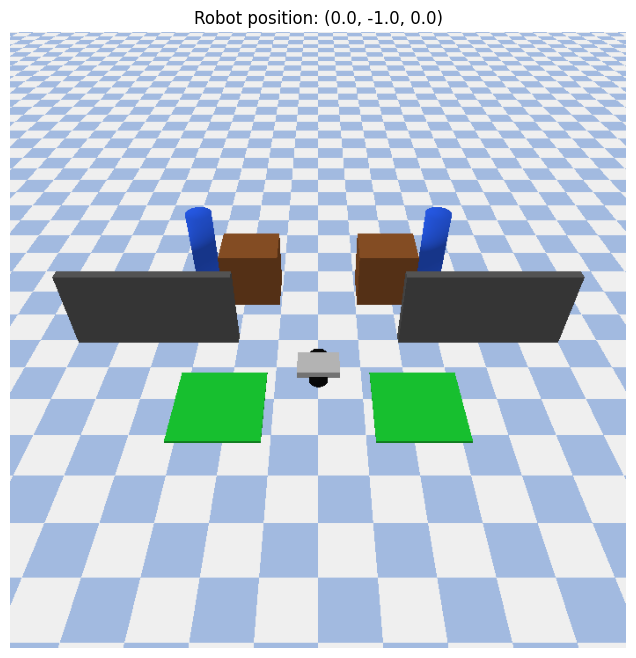

In [24]:
image_1 = render_scene(
    robot_position=(0.0, -1.0, 0.0),
    camera_position=(0, -10, 9),
    target_position=(0, 0, 0),
    filename=OUTPUT_DIR / "view_1.png"
)

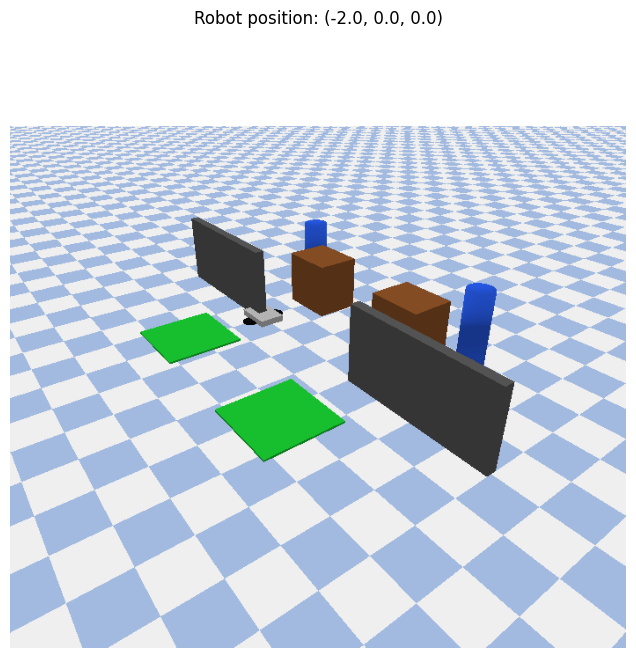

In [25]:
image_2 = render_scene(
    robot_position=(-2.0, 0.0, 0.0),
    camera_position=(10, -7, 7),
    target_position=(0, 0.5, 0),
    filename=OUTPUT_DIR / "view_2.png"
)

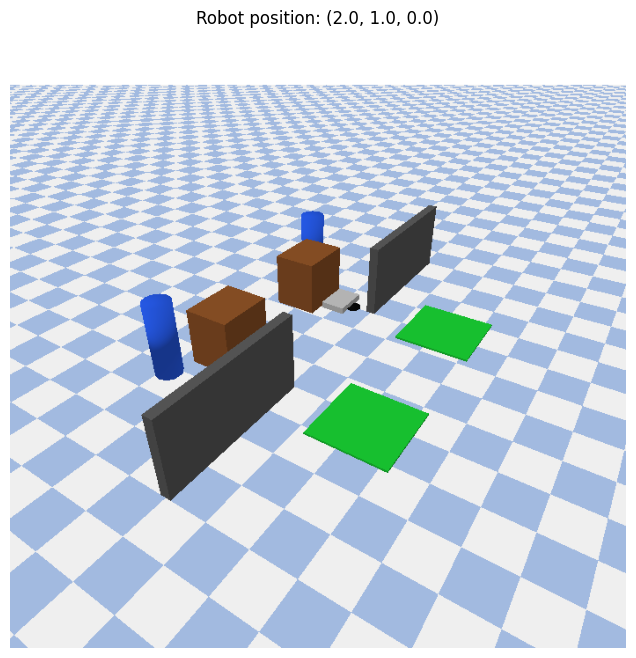

In [26]:
image_3 = render_scene(
    robot_position=(2.0, 1.0, 0.0),
    camera_position=(-10, -6, 8),
    target_position=(0, 0.5, 0),
    filename=OUTPUT_DIR / "view_3.png"
)

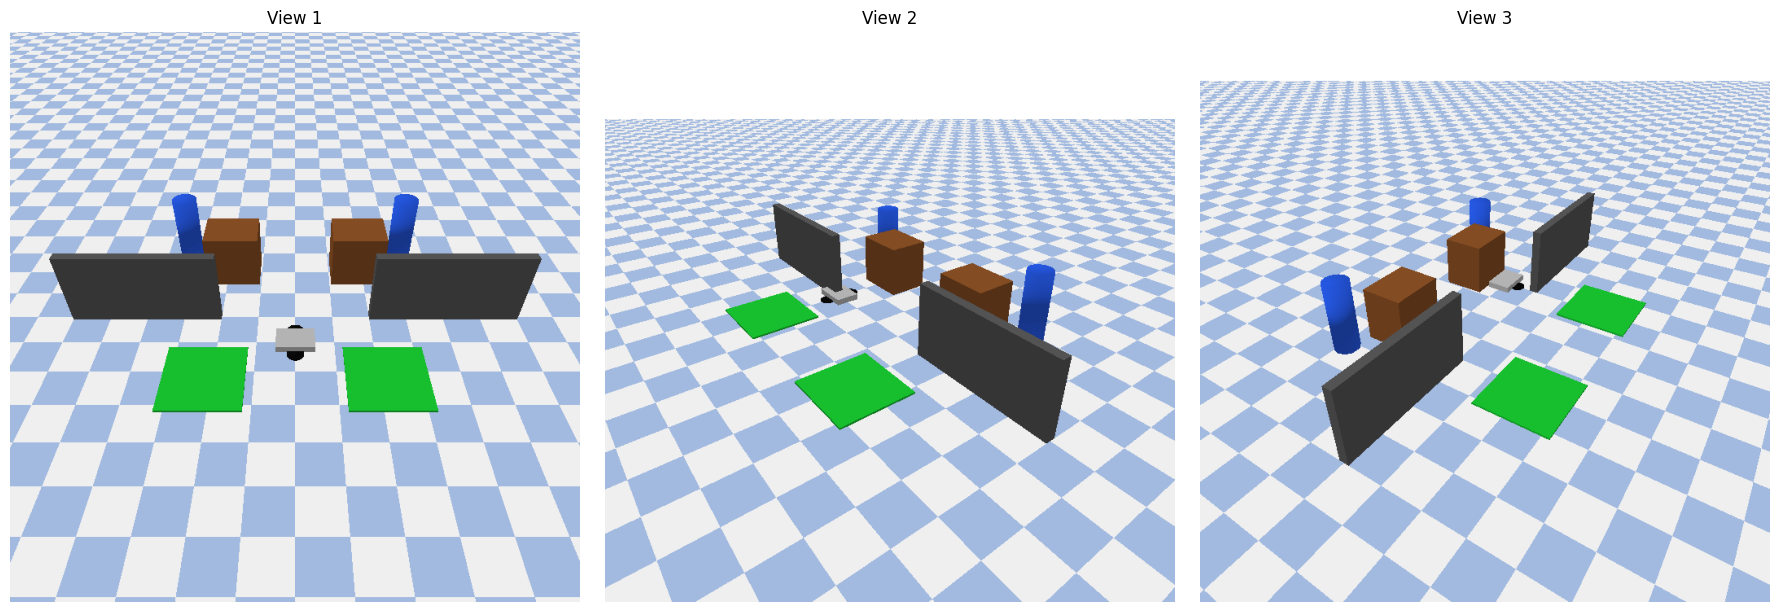

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, image, title in zip(
    axes,
    [image_1, image_2, image_3],
    ["View 1", "View 2", "View 3"]
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
def validate_scene():

    expected_objects = 8
    actual_objects = len(loaded_objects) - 1  # exclude robot

    assert actual_objects >= expected_objects, \
        "Scene contains fewer than eight simple objects."

    assert "robot" in loaded_objects, \
        "Robot was not loaded."

    required_roles = {"obstacle", "target", "landmark"}

    existing_roles = {
        metadata["role"]
        for name, metadata in semantic_objects.items()
        if name != "robot"
    }

    assert required_roles.issubset(existing_roles), \
        "Required semantic roles are missing."

    print("Scene validation PASSED.")
    print("Simple objects:", actual_objects)
    print("Robot present:", True)
    print("Semantic roles:", existing_roles)


validate_scene()

Scene validation PASSED.
Simple objects: 8
Robot present: True
Semantic roles: {'target', 'landmark', 'obstacle'}


In [29]:
for position in robot_positions:

    result = nearest_object(
        position,
        role="target"
    )

    print(
        f"Robot at {position} -> "
        f"nearest target = {result['object']}, "
        f"distance = {result['distance']:.2f} m"
    )

Robot at (0.0, -1.0, 0.0) -> nearest target = target_1, distance = 2.51 m
Robot at (-2.0, 0.0, 0.0) -> nearest target = target_1, distance = 2.21 m
Robot at (2.0, 1.0, 0.0) -> nearest target = target_2, distance = 3.21 m


In [30]:
import pandas as pd

semantic_table = []

for name, metadata in semantic_objects.items():

    position = object_positions[name]

    semantic_table.append({
        "Object": name,
        "Role": metadata["role"],
        "Type": metadata["type"],
        "X": position[0],
        "Y": position[1],
        "Z": position[2]
    })

semantic_df = pd.DataFrame(semantic_table)

display(semantic_df)

,Object,Role,Type,X,Y,Z
0,wall_1,obstacle,wall,-4.0,0.0,0.0
1,wall_2,obstacle,wall,4.0,0.0,0.0
2,storage_1,obstacle,storage,-1.8,2.0,0.0
3,storage_2,obstacle,storage,1.8,2.0,0.0
4,target_1,target,pickup_zone,-2.2,-2.2,0.0
5,target_2,target,pickup_zone,2.2,-2.2,0.0
6,landmark_1,landmark,reference,-3.2,2.8,0.0
7,landmark_2,landmark,reference,3.2,2.8,0.0
8,robot,agent,two_wheel_robot,0.0,-1.0,0.0


In [31]:
query_results = []

for position in robot_positions:

    result = nearest_object(
        position,
        role="target"
    )

    query_results.append({
        "Robot X": position[0],
        "Robot Y": position[1],
        "Nearest Target": result["object"],
        "Distance (m)": round(result["distance"], 3)
    })

query_df = pd.DataFrame(query_results)

display(query_df)

,Robot X,Robot Y,Nearest Target,Distance (m)
0,0.0,-1.0,target_1,2.506
1,-2.0,0.0,target_1,2.209
2,2.0,1.0,target_2,3.206


In [32]:
reflection = """
DESIGN REFLECTION

The environment was designed as a compact warehouse navigation scenario.
Four custom semantic object types were created: walls, storage blocks,
target zones and landmarks. A differential two-wheel robot was added as
the mobile agent.

A dictionary-based semantic representation was selected because it allows
each simulated body to retain a meaningful role independently of its
visual geometry. This makes later perception and decision-making extensions
easier.

The PyBullet DIRECT mode was used because the assignment requires
programmatic camera observation without relying on an interactive GUI.

Three camera viewpoints were implemented while keeping static objects
fixed and changing only the robot position. This approximates different
observations of the same environment during robot movement.

A nearest-target query was selected as the interaction mechanism because
it demonstrates how semantic information can support a robot-level
decision without requiring a full navigation planner.

Potential limitations include simplified robot dynamics, idealised object
geometry and the absence of realistic sensor noise. A future version could
introduce LiDAR/range sensing, collision-aware navigation and perception
uncertainty.
"""

print(reflection)


DESIGN REFLECTION

The environment was designed as a compact warehouse navigation scenario.
Four custom semantic object types were created: walls, storage blocks,
target zones and landmarks. A differential two-wheel robot was added as
the mobile agent.

A dictionary-based semantic representation was selected because it allows
each simulated body to retain a meaningful role independently of its
visual geometry. This makes later perception and decision-making extensions
easier.

The PyBullet DIRECT mode was used because the assignment requires
programmatic camera observation without relying on an interactive GUI.

Three camera viewpoints were implemented while keeping static objects
fixed and changing only the robot position. This approximates different
observations of the same environment during robot movement.

A nearest-target query was selected as the interaction mechanism because
it demonstrates how semantic information can support a robot-level
decision without requiring a full na

In [33]:
with open(OUTPUT_DIR / "semantic_metadata.json", "w") as f:
    json.dump(semantic_objects, f, indent=4)

print("Semantic metadata saved.")

Semantic metadata saved.


In [34]:
print("Generated output files:")

for file in OUTPUT_DIR.iterdir():
    print(" -", file.name)

Generated output files:
 - view_2.png
 - view_3.png
 - view_1.png
 - semantic_metadata.json
